In [3]:
#Clustering med KMeans

In [57]:
import pandas as pd 
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

In [33]:
df= sns.load_dataset("penguins").dropna()
df.head()

,species,island,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g,sex
0,Adelie,Torgersen,39.1,18.7,181.0,3750.0,Male
1,Adelie,Torgersen,39.5,17.4,186.0,3800.0,Female
2,Adelie,Torgersen,40.3,18.0,195.0,3250.0,Female
4,Adelie,Torgersen,36.7,19.3,193.0,3450.0,Female
5,Adelie,Torgersen,39.3,20.6,190.0,3650.0,Male


In [34]:
x= df[["bill_length_mm","bill_depth_mm","flipper_length_mm","body_mass_g"]]
x.head()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
0,39.1,18.7,181.0,3750.0
1,39.5,17.4,186.0,3800.0
2,40.3,18.0,195.0,3250.0
4,36.7,19.3,193.0,3450.0
5,39.3,20.6,190.0,3650.0


In [35]:
x_scaled= StandardScaler().fit_transform(x)


In [38]:
kmeans = KMeans(n_clusters= 3, random_state = 42)
df["KLuster"] = kmeans.fit_predict(x_scaled)

In [39]:
pd.crosstab(df["species"],df["KLuster"])

KLuster,0,1,2
species,,,
Adelie,124,0,22
Chinstrap,5,0,63
Gentoo,0,119,0


In [ ]:
sns.scatter

In [41]:
x.std()

bill_length_mm         5.468668
bill_depth_mm          1.969235
flipper_length_mm     14.015765
body_mass_g          805.215802
dtype: float64

In [42]:
df["KLuster_unscaled"] = kmeans.fit_predict(x)
pd.crosstab(df["species"],df["KLuster_unscaled"])

KLuster_unscaled,0,1,2
species,,,
Adelie,94,0,52
Chinstrap,46,0,22
Gentoo,0,80,39


In [43]:
## Tolka Kluster

In [49]:
df.groupby("KLuster")[x.columns].mean()

,bill_length_mm,bill_depth_mm,flipper_length_mm,body_mass_g
KLuster,,,,
0,38.276744,18.121705,188.627907,3593.798450
1,47.568067,14.996639,217.235294,5092.436975
2,47.662353,18.748235,196.917647,3898.235294


In [ ]:
kluster 0 - små pingviner med kort och djup nåbb och kort denor.
kluster 1- stor pingviner med låg och smal nåb och lpng fenor.
kluster 2- melstora pingviner med lång och djup nåb .

In [59]:
inertia = []
for k in range (2,9):
    km= KMeans(n_clusters=k,random_state= 42).fit(x_scaled)
    inertia.append(km.inertia_)
    print(k,round(km.inertia_),round(silhouette_score(x_scaled,km.labels_),2))

2 553 0.53
3 371 0.45
4 305 0.42
5 229 0.37
6 201 0.37
7 187 0.35
8 167 0.3


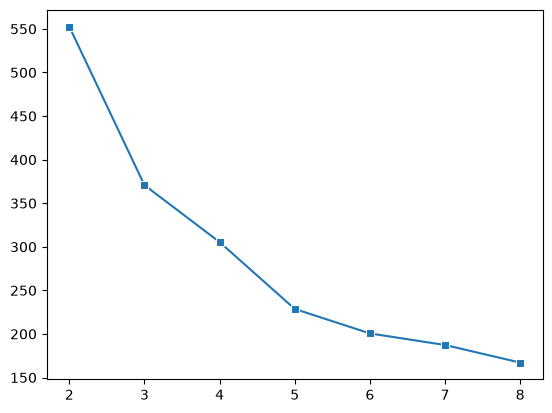

In [62]:
sns.lineplot ( x=range(2,9),y=inertia, marker="s");

In [65]:
pd.crosstab([df["species"],df["sex"]],KMeans(n_clusters=6,random_state= 42).fit(x_scaled))

col_0             KMeans(n_clusters=6, random_state=42)
species   sex                                          
Adelie    Female                                     73
          Male                                       73
Chinstrap Female                                     34
          Male                                       34
Gentoo    Female                                     58
          Male                                       61